# ЛР №2. Автоматическая суммаризация новостей (CNN/DailyMail)

Трек А, вариант 4 «Суммаризация или генерация текста», задача — автоматическая суммаризация.

Сравниваются: **RoBERTa-base** (экстрактивная суммаризация, дообучение на CNN/DailyMail), **Qwen3.6-35B-A3B** (локально через LM Studio, без дообучения), **GPT-6 Luna** (OpenAI API, без дообучения). **Lead-3** (первые три предложения статьи) — точка отсчёта, не модель.

## Окружение

Только для Google Colab: загрузка кода и библиотек. LM Studio в Colab недоступен — для Qwen используются сохранённые ответы из `outputs/generations`.

In [1]:
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/l1can13/llm-summarizer.git"
    if not Path("/content/lr2").exists():
        !git clone -q {REPO_URL} /content/lr2
    %cd /content/lr2
    !pip install -q rouge-score sacrebleu bert-score python-dotenv

Импорты, фиксация seed, проверка GPU.

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src import config as C, data, extractive as E, llm, metrics as M, viz

torch.manual_seed(C.SEED)
np.random.seed(C.SEED)
C.OUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 2)
pd.set_option("display.max_colwidth", 300)
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0))

torch 2.14.0+cu130 | GPU: NVIDIA GeForce RTX 4070


## Данные

CNN/DailyMail 3.0.0 с Hugging Face (`abisee/cnn_dailymail`, около 840 МБ). Если данные уже скачаны, шаг пропускается.

In [3]:
data.prepare_dataset()
raw = {s: data.load_split(s) for s in C.SPLITS}
pd.Series({s: len(f) for s, f in raw.items()}, name="статей")

train         287113
validation     13368
test           11490
Name: статей, dtype: int64

Пример: статья и эталонное резюме (highlights) — пункты, написанные редакцией.

In [4]:
ex = raw["validation"].iloc[0]
print(ex.article[:700], "...\n")
print(ex.highlights)

(CNN)Share, and your gift will be multiplied. That may sound like an esoteric adage, but when Zully Broussard selflessly decided to give one of her kidneys to a stranger, her generosity paired up with big data. It resulted in six patients receiving transplants. That surprised and wowed her. "I thought I was going to help this one person who I don't know, but the fact that so many people can have a life extension, that's pretty big," Broussard told CNN affiliate KGO. She may feel guided in her generosity by a higher power. "Thanks for all the support and prayers," a comment on a Facebook page in her name read. "I know this entire journey is much bigger than all of us. I also know I'm just the ...

Zully Broussard decided to give a kidney to a stranger .
A new computer program helped her donation spur transplants for six kidney patients .


## Анализ качества данных

Пустые тексты и дубликаты (по нормализованному тексту) внутри выборок и между ними.

In [5]:
hashes = {s: f.article.map(data.norm_hash) for s, f in raw.items()}
train_hashes = set(hashes["train"])
quality = pd.DataFrame({s: {
    "статей": len(f),
    "пустых статей": int((f.article.str.strip() == "").sum()),
    "пустых резюме": int((f.highlights.str.strip() == "").sum()),
    "повторов статей внутри выборки": int(hashes[s].duplicated().sum()),
    "повторов резюме внутри выборки": int(f.highlights.map(data.norm_hash).duplicated().sum()),
    "статей, совпадающих со статьями train": 0 if s == "train" else int(hashes[s].isin(train_hashes).sum()),
    "резюме длиннее 200 слов": int((f.highlights.str.split().str.len() > 200).sum()),
} for s, f in raw.items()})
quality

,train,validation,test
статей,287113,13368,11490
пустых статей,0,0,0
пустых резюме,0,0,0
повторов статей внутри выборки,3115,0,2
повторов резюме внутри выборки,4962,70,42
"статей, совпадающих со статьями train",0,1,0
резюме длиннее 200 слов,174,8,9


Служебные фрагменты в начале статей: шапка Daily Mail («By . Автор . PUBLISHED: … | UPDATED: …») и метка «(CNN) --».

In [6]:
pd.DataFrame({s: data.boilerplate_share(f.article) for s, f in raw.items()}).round(1)

,train,validation,test
"шапка Daily Mail («By . …»), %",34.2,0.0,0.0
"метка «(CNN)» в начале, %",19.5,7.1,7.2


Длины статей и эталонных резюме (в словах), число пунктов в резюме.

mean    50%     95%     max
train      article_words    691.9  632.0  1363.0  2347.0
           highlight_words   51.6   48.0    90.0  1296.0
           highlight_sents    3.8    4.0     6.0   128.0
validation article_words    676.0  608.0  1370.0  1917.0
           highlight_words   57.9   54.0    99.0  1440.0
           highlight_sents    4.1    4.0     6.0    34.0
test       article_words    683.5  613.0  1399.5  1954.0
           highlight_words   55.0   51.0    95.0   564.0
           highlight_sents    3.9    4.0     6.0    39.0

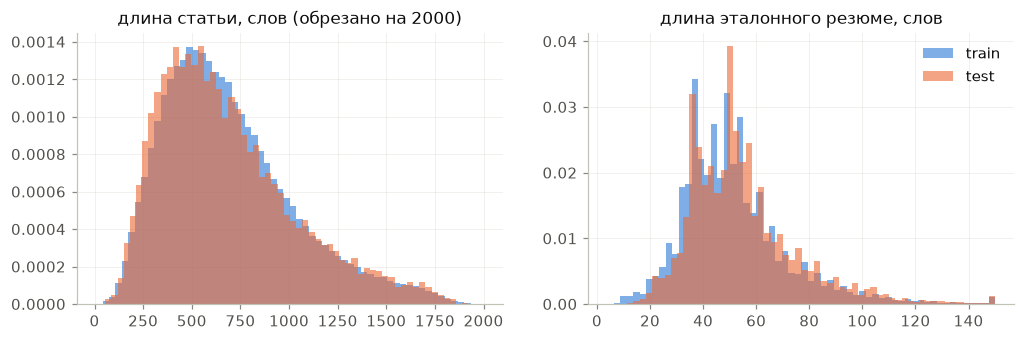

In [7]:
lengths = {s: data.length_stats(f) for s, f in raw.items()}
length_table = pd.concat({s: l.describe(percentiles=[0.5, 0.95]).T[["mean", "50%", "95%", "max"]] for s, l in lengths.items()}, axis=0)
display(length_table.round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for i, s in enumerate(["train", "test"]):
    axes[0].hist(lengths[s].article_words.clip(upper=2000), bins=60, alpha=0.6, density=True, color=viz.SERIES[i], label=s)
    axes[1].hist(lengths[s].highlight_words.clip(upper=150), bins=60, alpha=0.6, density=True, color=viz.SERIES[i], label=s)
axes[0].set_title("длина статьи, слов (обрезано на 2000)")
axes[1].set_title("длина эталонного резюме, слов")
axes[1].legend()
viz.save(fig, "lengths")
plt.show()

Окно RoBERTa (512 токенов) на валидационной выборке, используемой для выбора модели: сколько текста помещается и где находятся предложения, наиболее близкие к эталону («оракул» — жадный выбор до трёх предложений с максимальным ROUGE-1 + ROUGE-2).

In [8]:
tok = E.get_tokenizer()
val_eval = data.preprocess(data.sample(raw["validation"], C.VAL_SAMPLE), "val_eval", with_oracle_all=True)
art_tokens = np.array([len(t) for t in tok(val_eval.article.tolist(), add_special_tokens=False)["input_ids"]])
pd.Series({
    "токенов в статье, медиана": np.median(art_tokens),
    "статей длиннее 512 токенов, %": 100 * np.mean(art_tokens > C.MAX_TOKENS),
    "предложений в статье, среднее": val_eval.n_sent.mean(),
    "предложений в окне 512 токенов, среднее": val_eval.n_fit.mean(),
    "статей, где оракул берёт предложение вне окна, %": 100 * np.mean([max(o, default=-1) >= n for o, n in zip(val_eval.oracle_all, val_eval.n_fit)]),
}).round(1)

токенов в статье, медиана                           767.0
статей длиннее 512 токенов, %                        76.0
предложений в статье, среднее                        33.3
предложений в окне 512 токенов, среднее              17.1
статей, где оракул берёт предложение вне окна, %     32.9
dtype: float64

Насколько эталоны извлекаемы из текста: доля n-грамм эталона, которых нет в статье, и ROUGE для Lead-3 и оракула (верхняя граница экстрактивного подхода).

In [9]:
refs_val = val_eval.highlights.tolist()
novel = pd.Series({f"новых {n}-грамм в эталоне, %": np.mean([M.novel_ngram_share(h, a, n) for h, a in zip(val_eval.highlights, val_eval.article)])
                   for n in (1, 2, 3)})
display(novel.round(1))
pd.DataFrame({
    "Lead-3": M.rouge([data.lead(s) for s in val_eval.sentences], refs_val).mean(),
    "оракул в окне 512": M.rouge([data.oracle_summary(s, o) for s, o in zip(val_eval.sentences, val_eval.oracle)], refs_val).mean(),
    "оракул по всей статье": M.rouge([data.oracle_summary(s, o) for s, o in zip(val_eval.sentences, val_eval.oracle_all)], refs_val).mean(),
}).T

новых 1-грамм в эталоне, %    11.9
новых 2-грамм в эталоне, %    47.3
новых 3-грамм в эталоне, %    66.4
dtype: float64

,ROUGE-1,ROUGE-2,ROUGE-L
Lead-3,40.68,18.11,37.13
оракул в окне 512,55.49,32.27,51.55
оракул по всей статье,57.18,34.12,53.27


## Предобработка

Очистка: удаление шапки Daily Mail и метки «(CNN) --», нормализация пробелов. Разбиение на предложения — NLTK (предложения короче 3 слов отбрасываются). Для обучения RoBERTa — разметка «оракула» в пределах окна 512 токенов.

In [10]:
dm_example = raw["train"][raw["train"].article.str.contains("PUBLISHED: .", regex=False)].article.iloc[0]
print("до:   ", dm_example[:250])
print("после:", data.clean_article(dm_example)[:250])

до:    By . Alfonso Serrano F. PUBLISHED: . 13:46 EST, 8 March 2012 . | . UPDATED: . 14:02 EST, 8 March 2012 . A quick-thinking Texas kindergarten student is being credited with saving his choking friend's life by performing the Heimlich maneuver. Jasiah Ru
после: A quick-thinking Texas kindergarten student is being credited with saving his choking friend's life by performing the Heimlich maneuver. Jasiah Rubalcava, 5, was eating lunch at West Avenue Elementary School in San Antonio when he noticed that his fr


Предобработка всей обучающей выборки (около 10 мин; результат кэшируется).

In [11]:
train_prep = data.preprocess(raw["train"], "train")
print("статей:", len(train_prep), "| шапок после очистки:", sum(data.has_header(" ".join(s)) for s in train_prep.sentences[:20000]),
      "(проверено 20 000)")
train_prep.oracle.str.len().value_counts().sort_index().rename("предложений в разметке оракула")

статей: 287113 | шапок после очистки: 2 (проверено 20 000)


oracle
1     23789
2    101216
3    162108
Name: предложений в разметке оракула, dtype: int64

Очистка обучающей выборки: удаляются повторы статей, статьи, совпадающие со статьями validation/test, и примеры с эталоном длиннее 200 слов (в таких эталонах оказался текст статьи).

In [12]:
other = set(hashes["validation"]) | set(hashes["test"])
h = hashes["train"]
long_ref = lengths["train"].highlight_words > 200
keep = (~h.duplicated() & ~h.isin(other) & ~long_ref).values
cleaning = pd.Series({"повторы статей": int(h.duplicated().sum()), "совпадают со статьями validation/test": int(h.isin(other).sum()),
                      "эталон длиннее 200 слов": int(long_ref.sum()), "исключено всего": int((~keep).sum())})
train_prep = train_prep[keep].reset_index(drop=True)
cleaning["осталось статей"] = len(train_prep)
cleaning

повторы статей                             3115
совпадают со статьями validation/test         1
эталон длиннее 200 слов                     174
исключено всего                            3290
осталось статей                          283823
dtype: int64

Выборки: тест — случайные статьи официального test (одни и те же для всех моделей); валидация для RoBERTa — `val_eval`; для выбора промпта LLM — отдельные статьи официального validation.

In [13]:
test = data.preprocess(data.sample(raw["test"], C.TEST_SAMPLE), f"test_{C.TEST_SAMPLE}", with_oracle_all=True)
prompt_val = data.sample(raw["validation"][~raw["validation"].id.isin(val_eval.id)], C.PROMPT_VAL_SAMPLE)
test[["id"]].to_csv(C.OUT_DIR / "test_ids.csv", index=False)
pd.Series({"обучение RoBERTa": len(train_prep), "валидация RoBERTa": len(val_eval),
           "выбор промпта LLM": len(prompt_val), "тест (все модели)": len(test)}, name="статей")

обучение RoBERTa     283823
валидация RoBERTa      1000
выбор промпта LLM        50
тест (все модели)      1000
Name: статей, dtype: int64

Вход LLM — текст статьи, обрезанный до заданного числа слов; RoBERTa видит окно 512 токенов.

In [14]:
test_words = test.article.map(lambda a: len(data.clean_article(a).split()))
PROMPT_KW = {"n_sent": "3-4", "n_words": int(5 * round(lengths["train"].highlight_words.mean() / 5))}
pd.Series({
    "лимит слов на вход LLM": C.LLM_MAX_ARTICLE_WORDS,
    "тестовых статей, поместившихся целиком, %": 100 * (test_words <= C.LLM_MAX_ARTICLE_WORDS).mean(),
    "целевая длина резюме в промпте, слов": PROMPT_KW["n_words"],
}).round(1)

лимит слов на вход LLM                       1000.0
тестовых статей, поместившихся целиком, %      82.3
целевая длина резюме в промпте, слов           50.0
dtype: float64

## Гипотезы

Сформулированы после анализа данных, до экспериментов.

1. **H1.** Дообученная экстрактивная RoBERTa превзойдёт обе LLM без дообучения по ROUGE-2: эталоны во многом повторяют формулировки статьи (новых униграмм около 12 %), а ROUGE-2 вознаграждает точное совпадение словосочетаний.
2. **H2.** Обе LLM превзойдут RoBERTa по BERTScore: перефразирование сохраняет смысл, а BERTScore учитывает смысловую близость, а не только совпадение слов.
3. **H3.** GPT-6 Luna превзойдёт локальную Qwen3.6-35B-A3B (Q4_K_M) по ROUGE-L и BERTScore.
4. **H4.** На статьях длиннее 512 токенов преимущество LLM над RoBERTa по ROUGE-L будет больше, чем на коротких: RoBERTa видит только начало статьи.

## Модели

| Модель | Тип | Размер | Использование |
|---|---|---|---|
| RoBERTa-base | кодировщик-трансформер, экстрактивная суммаризация | 125 млн параметров | дообучается выбирать предложения (классификатор над векторами `<s>` предложений), выбор 3 предложений с блокировкой повторяющихся триграмм |
| Qwen3.6-35B-A3B | LLM, смесь экспертов | 35 млрд параметров, 3 млрд активных; GGUF Q4_K_M | локально в LM Studio, без дообучения, рассуждения отключены |
| GPT-6 Luna | LLM через OpenAI API | не раскрывается | без дообучения |
| Lead-3 | правило: первые 3 предложения | — | точка отсчёта |

In [15]:
print("RoBERTa-base + классификатор, параметров:", f"{sum(p.numel() for p in E.ExtSummarizer().parameters()) / 1e6:.1f} млн")

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 798.81it/s]

RoBERTa-base + классификатор, параметров: 124.1 млн


## Настройка гиперпараметров

**RoBERTa.** Пробные прогоны (около 15 мин): три значения lr, 1 эпоха на фиксированных 20 000 статей обучающей выборки, оценка на 500 статьях `val_eval`. Правило выбора — наибольшее среднее ROUGE-1, ROUGE-2, ROUGE-L.

In [16]:
PROBE_LRS = [1e-5, 2e-5, 5e-5]
probe_train = data.sample(train_prep, 20000)
probe_val = val_eval.iloc[:500]
probe = {}
for lr in PROBE_LRS:
    run = f"probe_lr{lr:g}"
    if E.finished(run):
        info = json.loads((C.OUT_DIR / "runs" / run / "params.json").read_text())
        print(f"{run}: уже выполнен")
    else:
        torch.manual_seed(C.SEED)
        _, info = E.train(E.ExtSummarizer(), run, probe_train, probe_val, tok, epochs=1, lr=lr, evals_per_epoch=1)
        torch.cuda.empty_cache()
    probe[lr] = info["best_val_ROUGE_mean"]
LR = max(probe, key=probe.get)
print("выбран lr =", LR)
pd.Series(probe, name="val, среднее ROUGE").rename_axis("lr")

probe_lr1e-05: 100%|██████████| 1250/1250 [04:44<00:00,  5.07it/s]

step 1250/1250 | train_loss 0.3592 | val R-1 42.83 R-2 20.30 R-L 39.42 | 4.7 min


probe_lr2e-05: 100%|██████████| 1250/1250 [04:42<00:00,  5.13it/s]

step 1250/1250 | train_loss 0.3547 | val R-1 42.77 R-2 20.30 R-L 39.36 | 4.7 min


probe_lr5e-05: 100%|██████████| 1250/1250 [04:50<00:00,  5.11it/s]

step 1250/1250 | train_loss 0.3515 | val R-1 43.00 R-2 20.47 R-L 39.48 | 4.8 min


probe_lr5e-05: 100%|██████████| 1250/1250 [04:51<00:00,  4.29it/s]

выбран lr = 5e-05


lr
1.00e-05    34.18
2.00e-05    34.15
5.00e-05    34.31
Name: val, среднее ROUGE, dtype: float64

**LLM.** Одинаковые для обеих моделей настройки: temperature 0 (если поддерживается), не более 256 новых токенов, рассуждения отключены. Промпт выбирается из двух вариантов на 50 статьях `prompt_val` по среднему ROUGE двух моделей.

In [17]:
for name in llm.PROMPTS:
    print(f"--- {name}:\n{llm.PROMPTS[name].format(article='<статья>', **PROMPT_KW)}\n")
print("Qwen:", C.QWEN_PARAMS, "\nGPT:", C.OPENAI_PARAMS)

--- basic:
Summarize the following news article in three sentences. Output only the summary.

Article:
<статья>

--- highlights:
Write the highlights of the news article below: 3-4 short sentences, about 50 words in total, stating the key facts (who, what, where, when). Use only information from the article. Output only the highlights, one sentence per line, without numbering or introduction.

Article:
<статья>

Qwen: {'temperature': 0, 'max_tokens': 256, 'reasoning_effort': 'none'} 
GPT: {'temperature': 0, 'max_completion_tokens': 256, 'reasoning_effort': 'none'}


Загрузка Qwen в LM Studio (около 2 мин): запуск сервера и загрузка модели, если она ещё не загружена.

In [18]:
print(llm.lmstudio_up())

Model loaded successfully in 2m 18.02s.
(20.55 GiB)
To use the model in the API/SDK, use the identifier "qwen/qwen3.6-35b-a3b".
IDENTIFIER              MODEL                   STATUS    SIZE        CONTEXT    PARALLEL    DEVICE    TTL
qwen/qwen3.6-35b-a3b    qwen/qwen3.6-35b-a3b    IDLE      22.07 GB    4096       4           Local


Выбор промпта (около 25 мин для Qwen, 1–2 мин для GPT).

In [19]:
refs_pv = prompt_val.highlights.tolist()
prompt_scores = {}
for name in llm.PROMPTS:
    q = llm.run(f"prompt_{name}_qwen", prompt_val, llm.lmstudio_client(), C.QWEN_MODEL, name, C.QWEN_PARAMS, PROMPT_KW)
    g = llm.run(f"prompt_{name}_gpt", prompt_val, llm.openai_client(), C.OPENAI_MODEL, name, C.OPENAI_PARAMS, PROMPT_KW, workers=8)
    prompt_scores[name] = {"Qwen": M.rouge(q.summary, refs_pv).mean().mean(), "GPT": M.rouge(g.summary, refs_pv).mean().mean()}
prompt_scores = pd.DataFrame(prompt_scores).T
prompt_scores["среднее"] = prompt_scores.mean(axis=1)
PROMPT = prompt_scores["среднее"].idxmax()
print("выбран промпт:", PROMPT)
prompt_scores

prompt_basic_qwen: готово 0, осталось 50


prompt_basic_qwen: 100%|██████████| 50/50 [13:08<00:00, 15.78s/it]


prompt_basic_gpt: готово 0, осталось 50


prompt_basic_gpt: 100%|██████████| 50/50 [00:15<00:00,  3.23it/s]


prompt_highlights_qwen: готово 0, осталось 50


prompt_highlights_qwen: 100%|██████████| 50/50 [11:23<00:00, 13.66s/it]


prompt_highlights_gpt: готово 0, осталось 50


prompt_highlights_gpt: 100%|██████████| 50/50 [00:12<00:00,  3.86it/s]


выбран промпт: highlights


,Qwen,GPT,среднее
basic,27.60,28.33,27.97
highlights,32.06,32.92,32.49


Выгрузка Qwen из видеопамяти перед обучением RoBERTa.

In [20]:
print(llm.lmstudio_down())

Unloading "qwen/qwen3.6-35b-a3b"...
Unloaded 1 model.


## Обучение RoBERTa

Около часа: вся обучающая выборка, 1 эпоха, выбранный lr, батч 16, AdamW (weight decay 0.01), разогрев 10% шагов и линейное затухание, bf16. Каждые 1/4 эпохи — оценка на `val_eval` (1000 статей); сохраняется лучший чекпойнт.

In [21]:
RUN = "roberta_ext"
if E.finished(RUN):
    hist = pd.read_csv(C.OUT_DIR / "runs" / RUN / "history.csv")
    info = json.loads((C.OUT_DIR / "runs" / RUN / "params.json").read_text())
    print("модель уже обучена")
else:
    torch.manual_seed(C.SEED)
    hist, info = E.train(E.ExtSummarizer(), RUN, train_prep, val_eval, tok, epochs=1, lr=LR, evals_per_epoch=4)
display(pd.Series({**info, "lr": f"{info['lr']:g}"}))
hist

roberta_ext:  25%|██▌       | 4435/17739 [16:26<43:07,  5.14it/s] 

step 4435/17739 | train_loss 0.3470 | val R-1 43.05 R-2 20.42 R-L 39.53 | 16.4 min


roberta_ext:  50%|█████     | 8870/17739 [31:25<28:44,  5.14it/s]  

step 8870/17739 | train_loss 0.3343 | val R-1 43.25 R-2 20.54 R-L 39.76 | 31.4 min


roberta_ext:  75%|███████▍  | 13304/17739 [46:20<14:23,  5.14it/s] 

...

roberta_ext: 100%|██████████| 17739/17739 [1:01:13<00:00,  5.14it/s]

step 17739/17739 | train_loss 0.3254 | val R-1 43.71 R-2 21.00 R-L 40.21 | 61.2 min


roberta_ext: 100%|██████████| 17739/17739 [1:01:15<00:00,  4.83it/s]


run                    roberta_ext
epochs                           1
lr                           5e-05
batch_size                      16
train_size                  283823
steps                        17739
train_min                    61.26
peak_mem_gb                   5.28
best_val_ROUGE_mean          34.97
dtype: object

,step,epoch,train_loss,val_ROUGE-1,val_ROUGE-2,val_ROUGE-L,val_ROUGE_mean,elapsed_min
0,4435,0.25,0.35,43.05,20.42,39.53,34.33,16.43
1,8870,0.50,0.33,43.25,20.54,39.76,34.52,31.42
2,13304,0.75,0.33,43.57,20.95,40.10,34.87,46.33
3,17739,1.00,0.33,43.71,21.00,40.21,34.97,61.21


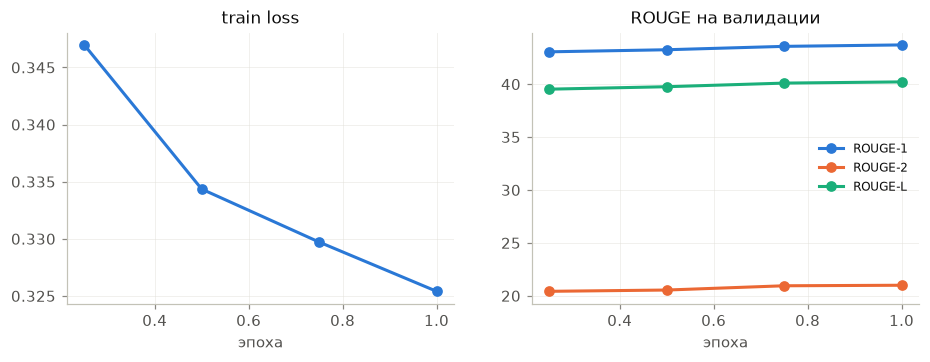

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(hist.epoch, hist.train_loss, marker="o", color=viz.SERIES[0])
axes[0].set_title("train loss")
for i, m in enumerate(["ROUGE-1", "ROUGE-2", "ROUGE-L"]):
    axes[1].plot(hist.epoch, hist[f"val_{m}"], marker="o", color=viz.SERIES[i], label=m)
axes[1].set_title("ROUGE на валидации")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel("эпоха")
viz.save(fig, "roberta_training")
plt.show()

## Генерация резюме на тестовой выборке

Все модели получают одни и те же статьи. Lead-3 и RoBERTa — несколько секунд.

In [23]:
gens = {}
gens["Lead-3"] = [data.lead(s) for s in test.sentences]
roberta = E.load_best(RUN)
gens["RoBERTa"], roberta_batch_s = E.predict(roberta, test, tok)
del roberta
torch.cuda.empty_cache()
print(f"RoBERTa, батч 32: {roberta_batch_s * 1000:.1f} мс на статью")

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 754.68it/s]


RoBERTa, батч 32: 27.8 мс на статью


Освобождение памяти: обучающие данные больше не нужны, а Qwen частично работает из оперативной памяти.

In [24]:
import gc

for name in ["train_prep", "probe_train", "raw", "hashes", "train_hashes", "lengths"]:
    globals().pop(name, None)
gc.collect()

20218

Загрузка Qwen в LM Studio.

In [25]:
print(llm.lmstudio_up())

Model loaded successfully in 2m 31.80s.
(20.55 GiB)
To use the model in the API/SDK, use the identifier "qwen/qwen3.6-35b-a3b".
IDENTIFIER              MODEL                   STATUS    SIZE        CONTEXT    PARALLEL    DEVICE    TTL
qwen/qwen3.6-35b-a3b    qwen/qwen3.6-35b-a3b    IDLE      22.07 GB    4096       4           Local


Qwen на тестовой выборке (около 14 с на статью, то есть около 4 ч на 1000 статей). Ответы сохраняются по одному: при остановке ячейку можно запустить снова.

In [26]:
qwen_test = llm.run("test_qwen", test, llm.lmstudio_client(), C.QWEN_MODEL, PROMPT, C.QWEN_PARAMS, PROMPT_KW)
gens["Qwen3.6-35B-A3B"] = qwen_test.summary.tolist()
qwen_test.finish_reason.value_counts()

test_qwen: готово 0, осталось 1000


test_qwen: 100%|██████████| 1000/1000 [3:56:13<00:00, 14.17s/it] 


finish_reason
stop    1000
Name: count, dtype: int64

Выгрузка Qwen.

In [27]:
print(llm.lmstudio_down())

Unloading "qwen/qwen3.6-35b-a3b"...
Unloaded 1 model.


GPT-6 Luna на тестовой выборке (10–20 мин, 8 параллельных запросов).

In [28]:
gpt_test = llm.run("test_gpt", test, llm.openai_client(), C.OPENAI_MODEL, PROMPT, C.OPENAI_PARAMS, PROMPT_KW, workers=8)
gens["GPT-6 Luna"] = gpt_test.summary.tolist()
print(f"стоимость: ${llm.openai_cost(gpt_test):.3f}")
gpt_test.finish_reason.value_counts()

test_gpt: готово 0, осталось 1000


test_gpt: 100%|██████████| 1000/1000 [03:45<00:00,  4.43it/s]

стоимость: $0.139


finish_reason
stop    1000
Name: count, dtype: int64

Проверка ответов: пустые резюме и обрывы по лимиту токенов.

In [29]:
pd.DataFrame({n: {"пустых": sum(not s.strip() for s in g), "средняя длина, слов": np.mean([len(s.split()) for s in g])}
              for n, g in gens.items()}).T

,пустых,"средняя длина, слов"
Lead-3,0.0,77.46
RoBERTa,0.0,72.49
Qwen3.6-35B-A3B,0.0,55.89
GPT-6 Luna,0.0,78.91


## Оценка

ROUGE-1/2/L (F1, со стеммингом; ROUGE-L — по предложениям), BLEU (sacreBLEU, по корпусу), BERTScore F1 (roberta-large, с поправкой на базовый уровень), средняя длина и доля новых биграмм (отсутствующих в статье).

In [30]:
refs, arts = test.highlights.tolist(), test.article.tolist()
results, per_doc = {}, {}
for name, preds in gens.items():
    results[name], per_doc[name] = M.evaluate(name, preds, refs, arts)
results = pd.DataFrame(results).T[["ROUGE-1", "ROUGE-2", "ROUGE-L", "BLEU", "BERTScore", "words", "novel_2grams"]]
results.loc["эталон", ["words", "novel_2grams"]] = [np.mean([len(M.words(r)) for r in refs]),
                                                     np.mean([M.novel_ngram_share(r, a) for r, a in zip(refs, arts)])]
results.to_csv(C.OUT_DIR / "test_metrics.csv")
results

Loading weights: 100%|██████████| 389/389 [00:00<00:00, 396.22it/s]


,ROUGE-1,ROUGE-2,ROUGE-L,BLEU,BERTScore,words,novel_2grams
Lead-3,39.57,17.05,35.93,11.38,24.87,79.64,0.00
RoBERTa,43.29,20.48,39.71,14.24,30.90,73.78,0.00
Qwen3.6-35B-A3B,39.04,13.45,35.43,8.41,28.80,57.77,57.54
GPT-6 Luna,39.97,15.04,36.08,8.37,27.53,82.01,52.68
эталон,NaN,NaN,NaN,NaN,NaN,52.68,48.36


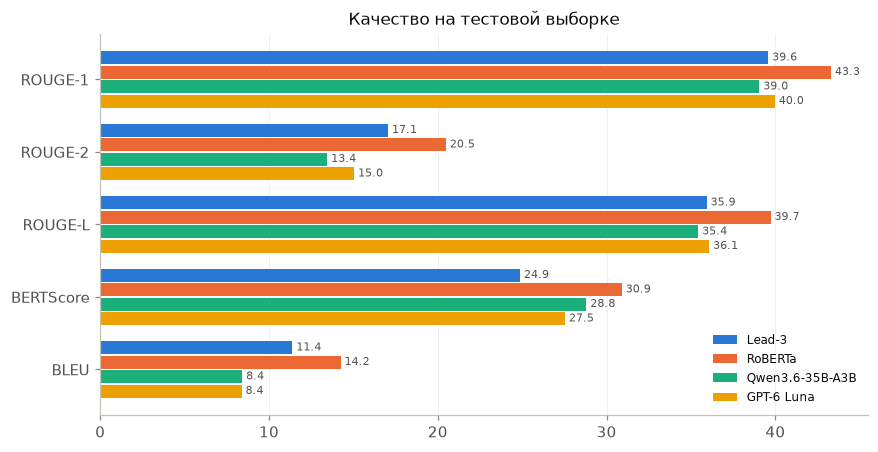

In [31]:
models = [n for n in gens]
fig, ax = plt.subplots(figsize=(9, 4.5))
viz.grouped_barh(ax, results.loc[models, ["ROUGE-1", "ROUGE-2", "ROUGE-L", "BERTScore", "BLEU"]].T)
ax.set_title("Качество на тестовой выборке")
viz.save(fig, "test_metrics")
plt.show()

Проверка H4: ROUGE-L отдельно для статей, помещающихся в окно RoBERTa (до 512 токенов), и для более длинных; разница «LLM − RoBERTa».

In [32]:
test_tokens = np.array([len(t) for t in tok([data.clean_article(a) for a in arts], add_special_tokens=False)["input_ids"]])
long_mask = test_tokens > C.MAX_TOKENS
by_len = pd.DataFrame({name: {"до 512 токенов": d["ROUGE-L"][~long_mask].mean(), "длиннее 512 токенов": d["ROUGE-L"][long_mask].mean()}
                       for name, d in per_doc.items()}).T
for name in ["Qwen3.6-35B-A3B", "GPT-6 Luna"]:
    by_len.loc[f"{name} − RoBERTa"] = by_len.loc[name] - by_len.loc["RoBERTa"]
by_len.loc["статей", :] = [int((~long_mask).sum()), int(long_mask.sum())]
by_len.to_csv(C.OUT_DIR / "rougeL_by_length.csv")
by_len

,до 512 токенов,длиннее 512 токенов
Lead-3,38.08,35.28
RoBERTa,41.50,39.17
Qwen3.6-35B-A3B,36.65,35.06
GPT-6 Luna,37.77,35.56
Qwen3.6-35B-A3B − RoBERTa,-4.84,-4.11
GPT-6 Luna − RoBERTa,-3.72,-3.61
статей,232.00,768.00


## Производительность

Задержка — медиана времени обработки одной статьи: RoBERTa — токенизация, прогон и выбор предложений (батч 1, GPU в bf16 и CPU в fp32); LLM — время ответа на запрос. Стоимость GPT — по токенам из ответа API и ценам из `config.py`.

In [33]:
roberta = E.load_best(RUN)
roberta_gpu = E.latency_ms(roberta, test, tok, "cuda")
roberta_cpu = E.latency_ms(roberta, test, tok, "cpu")
del roberta
torch.cuda.empty_cache()
perf = pd.DataFrame({
    "RoBERTa": {"где выполняется": "RTX 4070 / i7-12700F", "задержка, с": roberta_gpu / 1000, "задержка на CPU, с": roberta_cpu / 1000,
                "токенов вход / выход": "≤512 / –", "стоимость 1000 статей, $": 0.0,
                "обучение, мин": info["train_min"], "пик памяти GPU при обучении, ГБ": info["peak_mem_gb"]},
    "Qwen3.6-35B-A3B": {"где выполняется": "RTX 4070 + CPU (LM Studio)", "задержка, с": qwen_test.latency_s.median(),
                        "токенов вход / выход": f"{qwen_test.prompt_tokens.mean():.0f} / {qwen_test.completion_tokens.mean():.0f}",
                        "стоимость 1000 статей, $": 0.0},
    "GPT-6 Luna": {"где выполняется": "OpenAI API", "задержка, с": gpt_test.latency_s.median(),
                   "токенов вход / выход": f"{gpt_test.prompt_tokens.mean():.0f} / {gpt_test.completion_tokens.mean():.0f}",
                   "стоимость 1000 статей, $": llm.openai_cost(gpt_test) * 1000 / len(gpt_test)},
}).T
perf.to_csv(C.OUT_DIR / "performance.csv")
perf

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 585.86it/s]


,где выполняется,"задержка, с","задержка на CPU, с",токенов вход / выход,"стоимость 1000 статей, $","обучение, мин","пик памяти GPU при обучении, ГБ"
RoBERTa,RTX 4070 / i7-12700F,0.02,0.71,≤512 / –,0.0,61.26,5.28
Qwen3.6-35B-A3B,RTX 4070 + CPU (LM Studio),14.35,NaN,883 / 75,0.0,NaN,NaN
GPT-6 Luna,OpenAI API,1.68,NaN,855 / 106,0.14,NaN,NaN


## Примеры резюме

In [34]:
for k in [0, 1]:
    print("=" * 100)
    print("СТАТЬЯ:", data.clean_article(test.article[k])[:600], "...")
    print("\nЭТАЛОН:\n" + test.highlights[k])
    for name, g in gens.items():
        print(f"\n{name}:\n{g[k]}")

СТАТЬЯ: Down Augusta way they say the azaleas are in full bloom, which is more than can be said for England’s Justin Rose. A bruising Florida swing last month saw the Englishman fall outside the world’s top 10. For a player who has been virtually a fixture in the top five for the last three years it was certainly a dent to the ego, with the Masters now just around the corner. Rose’s solution to his miserable form — three missed cuts and a 55th-place finish at the Cadillac Championship in four PGA Tour starts — was the time-honoured one. For the past two weeks, the 34-year-old has spent long hours on t ...

ЭТАЛОН:
Justin Rose bounced back from Florida misery by carding 69 in Houston .
Three-time Masters champion Phil Mickelson enjoyed return to form .
Paul Casey celebrated last-gasp Masters invitation with fine round of 68 .

Lead-3:
Down Augusta way they say the azaleas are in full bloom, which is more than can be said for England’s Justin Rose.
A bruising Florida swing last month saw

## Сводная таблица

In [35]:
summary = pd.concat([results.loc[models], perf[["задержка, с", "стоимость 1000 статей, $"]]], axis=1)
summary.to_csv(C.OUT_DIR / "summary.csv")
summary

,ROUGE-1,ROUGE-2,ROUGE-L,BLEU,BERTScore,words,novel_2grams,"задержка, с","стоимость 1000 статей, $"
Lead-3,39.57,17.05,35.93,11.38,24.87,79.64,0.00,NaN,NaN
RoBERTa,43.29,20.48,39.71,14.24,30.90,73.78,0.00,0.02,0.0
Qwen3.6-35B-A3B,39.04,13.45,35.43,8.41,28.80,57.77,57.54,14.35,0.0
GPT-6 Luna,39.97,15.04,36.08,8.37,27.53,82.01,52.68,1.68,0.14
